# Vision — OCR (EasyOCR, model lokal)
**Kapan dipakai:** membaca teks dari gambar (foto papan, label, potongan kata) tanpa melatih
model sendiri.

**Langkah:** gambar → EasyOCR (bahasa en + id) → teks terbaca → dibandingkan dengan teks asli.

**Data demo:** kata yang dirender sendiri jadi gambar (sintetis, tanpa dataset). Ganti daftar
`WORDS` di Konfigurasi, atau isi `images` dengan foto sendiri (numpy array atau path file).
Bobot dari `pretrained/easyocr` (tanpa unduh).

In [1]:
from difflib import SequenceMatcher

import easyocr
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageDraw, ImageFont

## Konfigurasi

In [2]:
EASYOCR_FOLDER = "Z:/GEMASTIK-DATABASE/pretrained/easyocr"
LANGUAGES = ["en", "id"]
WORDS = ["selamat", "pagi", "gemastik", "database", "jakarta", "bandung",
         "sepeda", "rumah", "hello", "vision", "model", "hasil"]

## Buat data demo (render kata jadi gambar)

In [3]:
font = ImageFont.load_default(size=36)
images = []
for word in WORDS:
    image = Image.new("L", (360, 90), 255)
    drawer = ImageDraw.Draw(image)
    drawer.text((20, 20), word, fill=0, font=font)
    images.append(np.asarray(image))
print("jumlah gambar:", len(images), "| ukuran:", images[0].shape)

jumlah gambar: 12 | ukuran: (90, 360)


## Lihat gambar

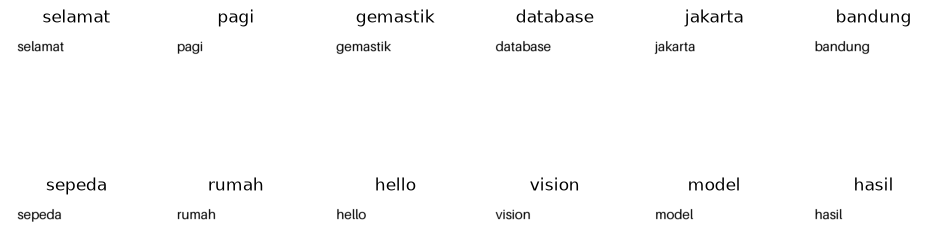

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(12, 4))
for ax, image, word in zip(axes.flat, images, WORDS):
    ax.imshow(image, cmap="gray")
    ax.set_title(word)
    ax.axis("off")
plt.show()

## Model EasyOCR (offline)

In [5]:
reader = easyocr.Reader(LANGUAGES, gpu=torch.cuda.is_available(),
                        model_storage_directory=EASYOCR_FOLDER,
                        user_network_directory=EASYOCR_FOLDER,
                        download_enabled=False, verbose=False)

## Baca teks + evaluasi
- **benar** = teks terbaca persis sama dengan teks asli.
- **mirip** = kemiripan huruf 0–1 (1 = sama persis).

In [6]:
read_texts = []
is_correct = []
similarity = []
for image, word in zip(images, WORDS):
    pieces = reader.readtext(image, detail=0)        # daftar potongan teks
    text = " ".join(pieces)
    text = text.strip().lower()
    read_texts.append(text)
    is_correct.append(text == word)
    similarity.append(SequenceMatcher(None, text, word).ratio())
print("akurasi kata persis:", round(np.mean(is_correct), 4))
print("kemiripan rata-rata:", round(np.mean(similarity), 4))

akurasi kata persis: 1.0
kemiripan rata-rata: 1.0


## Hasil

In [7]:
result = pd.DataFrame()
result["teks_asli"] = WORDS
result["teks_terbaca"] = read_texts
result["mirip"] = similarity
result.to_csv("hasil.csv", index=False)
result

,teks_asli,teks_terbaca,mirip
0,selamat,selamat,1.0
1,pagi,pagi,1.0
2,gemastik,gemastik,1.0
3,database,database,1.0
4,jakarta,jakarta,1.0
5,bandung,bandung,1.0
6,sepeda,sepeda,1.0
7,rumah,rumah,1.0
8,hello,hello,1.0
9,vision,vision,1.0
